# LAB 1 - Bài 2 (Trang 37, 38): Luật kết hợp trên dữ liệu Online Retail
SV: Hồng Kim Dung - 6451071009

In [1]:
!pip install -q mlxtend openpyxl
import numpy as np
import pandas as pd
import time
import matplotlib.pyplot as plt
import seaborn as sns
from mlxtend.frequent_patterns import apriori, fpgrowth, association_rules
import warnings; warnings.filterwarnings("ignore")
print("Hồng Kim Dung - 6451071009")

Hồng Kim Dung - 6451071009


## Câu 1: Đọc dữ liệu và tiền xử lý (yêu cầu 1, 2)

In [2]:
print("Hồng Kim Dung - 6451071009")

df = pd.read_excel("Online Retail.xlsx")
print(df.shape)
df.head()

Hồng Kim Dung - 6451071009
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [3]:
print("Hồng Kim Dung - 6451071009")

df["Description"] = df["Description"].str.strip()          # cắt ký tự thừa ở tên mặt hàng
df = df.dropna(subset=["InvoiceNo"])                        # xóa dòng không có số hóa đơn
df["InvoiceNo"] = df["InvoiceNo"].astype("str")             # chuyển về kiểu chuỗi
print(df.shape); df.info()

Hồng Kim Dung - 6451071009
(541909, 8)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540454 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


## Câu 2: Xóa hóa đơn tín dụng và thống kê theo quốc gia (yêu cầu 3, 4)

In [4]:
print("Hồng Kim Dung - 6451071009")

df = df[~df["InvoiceNo"].str.contains("C")]                 # hóa đơn tín dụng chứa ký tự 'C'
print(df.shape)
df["Country"].value_counts()

Hồng Kim Dung - 6451071009
(532621, 8)


,count
Country,
United Kingdom,487622
Germany,9042
France,8408
EIRE,7894
Spain,2485
Netherlands,2363
Belgium,2031
Switzerland,1967
Portugal,1501


## Câu 3: Lấy dữ liệu United Kingdom, gom nhóm, chuyển dạng hot encoding (yêu cầu 5, 6)

In [5]:
print("Hồng Kim Dung - 6451071009")

uk = df[df["Country"] == "United Kingdom"]
grouped = uk.groupby(["InvoiceNo","Description"])["Quantity"].sum()
grouped.head(10)

Hồng Kim Dung - 6451071009


InvoiceNo  Description                        
536365     CREAM CUPID HEARTS COAT HANGER          8
           GLASS STAR FROSTED T-LIGHT HOLDER       6
           KNITTED UNION FLAG HOT WATER BOTTLE     6
           RED WOOLLY HOTTIE WHITE HEART.          6
           SET 7 BABUSHKA NESTING BOXES            2
           WHITE HANGING HEART T-LIGHT HOLDER      6
           WHITE METAL LANTERN                     6
536366     HAND WARMER RED POLKA DOT               6
           HAND WARMER UNION JACK                  6
536367     ASSORTED COLOUR BIRD ORNAMENT          32
Name: Quantity, dtype: int64

In [6]:
print("Hồng Kim Dung - 6451071009")

# Mỗi dòng là một hóa đơn, mỗi cột là một mặt hàng, giá trị là tổng số lượng mua
basket = grouped.unstack().fillna(0)
print(basket.shape)
basket.iloc[:5, :6]

Hồng Kim Dung - 6451071009
(18667, 4175)


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,0.0,0.0,0.0,0.0,0.0,0.0
536366,0.0,0.0,0.0,0.0,0.0,0.0
536367,0.0,0.0,0.0,0.0,0.0,0.0
536368,0.0,0.0,0.0,0.0,0.0,0.0
536369,0.0,0.0,0.0,0.0,0.0,0.0


## Câu 4: Chuyển sang one-hot encoding và xóa POSTAGE (yêu cầu 7, 8)

In [7]:
print("Hồng Kim Dung - 6451071009")

# Giá trị >= 1 -> 1 (True), ngược lại -> 0 (False)
basket_sets = (basket >= 1).astype(bool)
print(basket_sets.shape)
basket_sets.iloc[:5, :6]

Hồng Kim Dung - 6451071009
(18667, 4175)


Description,*Boombox Ipod Classic,*USB Office Mirror Ball,10 COLOUR SPACEBOY PEN,12 COLOURED PARTY BALLOONS,12 DAISY PEGS IN WOOD BOX,12 EGG HOUSE PAINTED WOOD
InvoiceNo,,,,,,
536365,False,False,False,False,False,False
536366,False,False,False,False,False,False
536367,False,False,False,False,False,False
536368,False,False,False,False,False,False
536369,False,False,False,False,False,False


In [8]:
print("Hồng Kim Dung - 6451071009")

basket_sets = basket_sets.drop("POSTAGE", axis=1)           # POSTAGE là cước phí, không phải mặt hàng
print("POSTAGE" in basket_sets.columns, basket_sets.shape)

Hồng Kim Dung - 6451071009
False (18667, 4174)


## Câu 5: Apriori, luật kết hợp và biểu đồ (yêu cầu 9, 10, 11)

In [9]:
print("Hồng Kim Dung - 6451071009")

t0 = time.time()
frequent_itemsets = apriori(basket_sets, min_support=0.03, use_colnames=True)
t_apriori = time.time() - t0
frequent_itemsets["length"] = frequent_itemsets["itemset" if "itemset" in frequent_itemsets else "itemsets"].apply(len)
print("Số tập phổ biến:", len(frequent_itemsets), "| thời gian Apriori: %.2f giây" % t_apriori)
frequent_itemsets.sort_values("support", ascending=False).head(15)

Hồng Kim Dung - 6451071009
Số tập phổ biến: 131 | thời gian Apriori: 0.54 giây


,support,itemsets,length
118,0.116034,(WHITE HANGING HEART T-LIGHT HOLDER),1
52,0.103820,(JUMBO BAG RED RETROSPOT),1
95,0.090266,(REGENCY CAKESTAND 3 TIER),1
84,0.085391,(PARTY BUNTING),1
69,0.074570,(LUNCH BAG RED RETROSPOT),1
7,0.073445,(ASSORTED COLOUR BIRD ORNAMENT),1
103,0.066481,(SET OF 3 CAKE TINS PANTRY DESIGN),1
75,0.065302,(NATURAL SLATE HEART CHALKBOARD),1
63,0.065142,(LUNCH BAG BLACK SKULL.),1
35,0.062356,(HEART OF WICKER SMALL),1


In [10]:
print("Hồng Kim Dung - 6451071009")

rules = association_rules(frequent_itemsets, metric="confidence", min_threshold=0.5)
print("Số luật:", len(rules))
rules[["antecedents","consequents","support","confidence","lift"]]

Hồng Kim Dung - 6451071009
Số luật: 10


,antecedents,consequents,support,confidence,lift
0,(ALARM CLOCK BAKELIKE GREEN),(ALARM CLOCK BAKELIKE RED),0.030160,0.642694,12.900183
1,(ALARM CLOCK BAKELIKE RED),(ALARM CLOCK BAKELIKE GREEN),0.030160,0.605376,12.900183
2,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.030910,0.617773,16.403939
3,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.030910,0.820768,16.403939
4,(GREEN REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER),0.037553,0.750535,14.639752
5,(ROSES REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.037553,0.732497,14.639752
6,(JUMBO BAG BAROQUE BLACK WHITE),(JUMBO BAG RED RETROSPOT),0.030535,0.626374,6.033290
7,(JUMBO BAG PINK POLKADOT),(JUMBO BAG RED RETROSPOT),0.042053,0.677308,6.523895
8,(JUMBO SHOPPER VINTAGE RED PAISLEY),(JUMBO BAG RED RETROSPOT),0.035196,0.579876,5.585425
9,(JUMBO STORAGE BAG SUKI),(JUMBO BAG RED RETROSPOT),0.037392,0.617699,5.949737


Hồng Kim Dung - 6451071009


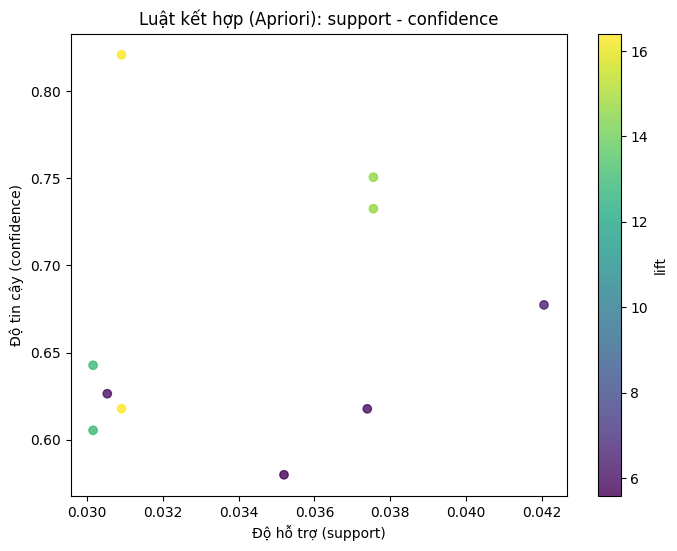

In [11]:
print("Hồng Kim Dung - 6451071009")

plt.figure(figsize=(8,6))
plt.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="viridis", alpha=.8)
plt.colorbar(label="lift"); plt.xlabel("Độ hỗ trợ (support)"); plt.ylabel("Độ tin cậy (confidence)")
plt.title("Luật kết hợp (Apriori): support - confidence"); plt.show()

## Câu 6: FP-Growth và so sánh với Apriori (yêu cầu 12)

In [12]:
print("Hồng Kim Dung - 6451071009")

t0 = time.time()
fp_itemsets = fpgrowth(basket_sets, min_support=0.03, use_colnames=True)
t_fp = time.time() - t0
fp_rules = association_rules(fp_itemsets, metric="confidence", min_threshold=0.5)
print("FP-Growth: %d tập phổ biến, %d luật, %.2f giây" % (len(fp_itemsets), len(fp_rules), t_fp))
print("Apriori  : %d tập phổ biến, %d luật, %.2f giây" % (len(frequent_itemsets), len(rules), t_apriori))
fp_rules[["antecedents","consequents","support","confidence","lift"]]

Hồng Kim Dung - 6451071009
FP-Growth: 131 tập phổ biến, 10 luật, 3.74 giây
Apriori  : 131 tập phổ biến, 10 luật, 0.54 giây


,antecedents,consequents,support,confidence,lift
0,(JUMBO BAG PINK POLKADOT),(JUMBO BAG RED RETROSPOT),0.042053,0.677308,6.523895
1,(JUMBO STORAGE BAG SUKI),(JUMBO BAG RED RETROSPOT),0.037392,0.617699,5.949737
2,(JUMBO BAG BAROQUE BLACK WHITE),(JUMBO BAG RED RETROSPOT),0.030535,0.626374,6.033290
3,(JUMBO SHOPPER VINTAGE RED PAISLEY),(JUMBO BAG RED RETROSPOT),0.035196,0.579876,5.585425
4,(ALARM CLOCK BAKELIKE GREEN),(ALARM CLOCK BAKELIKE RED),0.030160,0.642694,12.900183
5,(ALARM CLOCK BAKELIKE RED),(ALARM CLOCK BAKELIKE GREEN),0.030160,0.605376,12.900183
6,(GREEN REGENCY TEACUP AND SAUCER),(ROSES REGENCY TEACUP AND SAUCER),0.037553,0.750535,14.639752
7,(ROSES REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.037553,0.732497,14.639752
8,(GREEN REGENCY TEACUP AND SAUCER),(PINK REGENCY TEACUP AND SAUCER),0.030910,0.617773,16.403939
9,(PINK REGENCY TEACUP AND SAUCER),(GREEN REGENCY TEACUP AND SAUCER),0.030910,0.820768,16.403939


In [13]:
print("Hồng Kim Dung - 6451071009")

col = "itemsets" if "itemsets" in fp_itemsets else "itemset"
a = set(frozenset(x) for x in frequent_itemsets[col]); b = set(frozenset(x) for x in fp_itemsets[col])
print("Hai thuật toán cho cùng tập phổ biến:", a == b)
ra = set((frozenset(x), frozenset(y)) for x, y in zip(rules["antecedents"], rules["consequents"]))
rb = set((frozenset(x), frozenset(y)) for x, y in zip(fp_rules["antecedents"], fp_rules["consequents"]))
print("Hai thuật toán cho cùng tập luật:", ra == rb)

Hồng Kim Dung - 6451071009
Hai thuật toán cho cùng tập phổ biến: True
Hai thuật toán cho cùng tập luật: True
